# Steam – Le marché du jeu vidéo vu par 55 000 jeux (PySpark)

**Contexte.** Ubisoft prépare un nouveau jeu et veut comprendre l'écosystème Steam : quels facteurs jouent sur la popularité et les ventes d'un jeu, et quelles sont les tendances du marché.

**Données.** Export de l'API Steam/SteamSpy : un document JSON par jeu, avec un schéma imbriqué (`data.platforms`, `data.tags`, listes de catégories, genres et langues en texte).

**Outil.** Toute la préparation et les agrégations sont faites en **PySpark** (DataFrame API, `explode`, `split`, `getField`, fonctions de date et de texte, `groupBy`). Seuls les résultats agrégés, de quelques dizaines de lignes, passent en pandas pour les graphiques.

> Ce notebook a été exécuté sur un Spark local. Il tourne tel quel dans Databricks, où l'objet `spark` existe déjà ; on peut y remplacer les graphiques matplotlib par `display(df)` et l'outil de visualisation Databricks. La publication des notebooks Databricks n'étant plus disponible, les sorties de cellules sont fournies en captures (`captures/`) et en export HTML.

**Plan.** 1. Chargement et nettoyage · 2. Vue macro · 3. Genres · 4. Plateformes · 5. Ce qui fait un jeu populaire · 6. Conclusions pour Ubisoft

In [1]:
import warnings
warnings.filterwarnings("ignore")
from pyspark.sql import SparkSession, functions as F, Window
import pandas as pd
import matplotlib.pyplot as plt

spark = (SparkSession.builder.master("local[*]").appName("steam-eda")
         .config("spark.driver.memory", "4g").config("spark.ui.showConsoleProgress", "false").getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

def barh(pdf, x, y, title, xlabel="", color="#4c72b0", fmt="{:,.0f}"):
    """Barres horizontales triées, valeurs affichées."""
    pdf = pdf.iloc[::-1]
    fig, ax = plt.subplots(figsize=(8, 0.38 * len(pdf) + 1))
    ax.barh(pdf[y].astype(str), pdf[x], color=color)
    for i, v in enumerate(pdf[x]):
        ax.text(v, i, " " + fmt.format(v), va="center", fontsize=9)
    ax.set(title=title, xlabel=xlabel)
    plt.show()

raw = spark.read.json("data/steam_game_output.json")
raw.printSchema()

Picked up JAVA_TOOL_OPTIONS: -Djavax.net.ssl.trustStore=/etc/ssl/certs/java/cacerts -Djavax.net.ssl.trustStoreType=JKS -Dhttps.proxyHost=127.0.0.1 -Dhttps.proxyPort=41493 -Dhttp.nonProxyHosts=localhost|127.0.0.1|::1|127.*|0.*|::|169.254.*|api.anthropic.com|api-staging.anthropic.com|api-pr-preview.anthropic.com|mcp-proxy.anthropic.com|mcp-proxy-staging.anthropic.com|registry.npmjs.org|jsr.io|npm.jsr.io|pypi.org|files.pythonhosted.org|index.crates.io|proxy.golang.org|host.docker.internal|10.*|172.16.*|172.17.*|172.18.*|172.19.*|172.20.*|172.21.*|172.22.*|172.23.*|172.24.*|172.25.*|172.26.*|172.27.*|172.28.*|172.29.*|172.30.*|172.31.*|192.168.*|100.64.0.0/10|*.svc.cluster.local|*.svc.cluster.local -Djdk.http.auth.tunneling.disabledSchemes= -Djdk.http.auth.proxying.disabledSchemes=
Picked up _JAVA_OPTIONS: -XX:+UnlockDiagnosticVMOptions -XX:DisableIntrinsic=_base64_encodeBlock,_base64_decodeBlock
Picked up JAVA_TOOL_OPTIONS: -Djavax.net.ssl.trustStore=/etc/ssl/certs/java/cacerts -Djavax.ne

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/11/18 23:33:39 WARN Utils: Your hostname, vm, resolves to a loopback address: 127.0.0.1; using 192.0.2.2 instead (on interface eth0)
26/11/18 23:33:39 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/11/18 23:33:40 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


root
 |-- data: struct (nullable = true)
 |    |-- appid: long (nullable = true)
 |    |-- categories: array (nullable = true)
 |    |    |-- element: string (containsNull = true)
 |    |-- ccu: long (nullable = true)
 |    |-- developer: string (nullable = true)
 |    |-- discount: string (nullable = true)
 |    |-- genre: string (nullable = true)
 |    |-- header_image: string (nullable = true)
 |    |-- initialprice: string (nullable = true)
 |    |-- languages: string (nullable = true)
 |    |-- name: string (nullable = true)
 |    |-- negative: long (nullable = true)
 |    |-- owners: string (nullable = true)
 |    |-- platforms: struct (nullable = true)
 |    |    |-- linux: boolean (nullable = true)
 |    |    |-- mac: boolean (nullable = true)
 |    |    |-- windows: boolean (nullable = true)
 |    |-- positive: long (nullable = true)
 |    |-- price: string (nullable = true)
 |    |-- publisher: string (nullable = true)
 |    |-- release_date: string (nullable = true)
 |    |-

## 1. Chargement et nettoyage

In [2]:
df = (raw.select("data.*")
      .filter(F.col("type") == "game")                                   # 1 « hardware » écarté
      .withColumn("price_usd", F.expr("try_cast(price AS double)") / 100)        # prix stocké en cents, en texte
      .withColumn("initial_usd", F.expr("try_cast(initialprice AS double)") / 100)
      .withColumn("discount", F.expr("try_cast(discount AS int)"))
      .withColumn("required_age", F.expr(r"try_cast(regexp_extract(required_age, '(\\d+)', 1) AS int)"))
      .withColumn("release", F.coalesce(F.expr("try_to_date(release_date, 'yyyy/M/d')"),   # formats mixtes : jour absent
                                         F.expr("try_to_date(release_date, 'yyyy/M')")))
      .withColumn("year", F.year("release"))
      # owners = "20,000 .. 50,000" -> bornes numériques et milieu de fourchette
      .withColumn("owners_low", F.regexp_replace(F.split("owners", r" \.\. ").getItem(0), ",", "").try_cast("long"))
      .withColumn("owners_high", F.regexp_replace(F.split("owners", r" \.\. ").getItem(1), ",", "").try_cast("long"))
      .withColumn("owners_mid", (F.col("owners_low") + F.col("owners_high")) / 2)
      .withColumn("reviews", F.col("positive") + F.col("negative"))
      .withColumn("positive_ratio", F.when(F.col("reviews") > 0, F.col("positive") / F.col("reviews")))
      .withColumn("genres", F.array_remove(F.split(F.coalesce("genre", F.lit("")), r",\s*"), ""))
      .withColumn("langs", F.array_remove(F.split(F.regexp_replace(F.coalesce("languages", F.lit("")), r"\[b\]\*\[/b\]|\*", ""), r",\s*"), ""))
      .withColumn("n_langs", F.size("langs"))
      .withColumn("windows", F.col("platforms").getField("windows"))
      .withColumn("mac", F.col("platforms").getField("mac"))
      .withColumn("linux", F.col("platforms").getField("linux"))
      .withColumn("n_platforms", F.col("windows").cast("int") + F.col("mac").cast("int") + F.col("linux").cast("int"))
      .withColumn("est_revenue", F.col("owners_mid") * F.col("price_usd"))   # proxy grossier : propriétaires × prix actuel
      .cache())

n = df.count()
print(f"{n:,} jeux")
qual = df.select(
    F.round(F.avg(F.col("release").isNull().cast("int")) * 100, 2).alias("% date illisible"),
    F.round(F.avg((F.col("publisher") == "").cast("int")) * 100, 2).alias("% sans éditeur"),
    F.round(F.avg((F.size("genres") == 0).cast("int")) * 100, 2).alias("% sans genre"),
    F.round(F.avg((F.col("reviews") == 0).cast("int")) * 100, 2).alias("% sans avis"))
qual.show()
df.select("name", "price_usd", "owners", "owners_mid", "year", "genres", "n_langs", "n_platforms", "positive_ratio").show(5, truncate=40)

55,690 jeux


+----------------+--------------+------------+-----------+
|% date illisible|% sans éditeur|% sans genre|% sans avis|
+----------------+--------------+------------+-----------+
|            0.18|          0.24|        0.29|       0.29|
+----------------+--------------+------------+-----------+

+---------------------------+---------+------------------------+----------+----+-------------------------------------+-------+-----------+------------------+
|                       name|price_usd|                  owners|owners_mid|year|                               genres|n_langs|n_platforms|    positive_ratio|
+---------------------------+---------+------------------------+----------+----+-------------------------------------+-------+-----------+------------------+
|             Counter-Strike|     9.99|10,000,000 .. 20,000,000|     1.5E7|2000|                             [Action]|      8|          3|0.9748127549487923|
|                  ASCENXION|     9.99|             0 .. 20,000|   10000

**Lecture.** 55 690 jeux (un matériel écarté). Les données sont propres : moins de 0,3 % de dates illisibles, d'éditeurs ou de genres manquants. Trois transformations étaient nécessaires :
- le **prix** est stocké en centimes, sous forme de texte ;
- le **nombre de propriétaires** est une fourchette (« 20,000 .. 50,000 ») : on garde les deux bornes et le milieu ;
- les **genres et les langues** sont des listes dans une chaîne de caractères : `split` puis `explode` pour les compter.

## 2. Vue macro

### 2.1 Quels éditeurs publient le plus ?

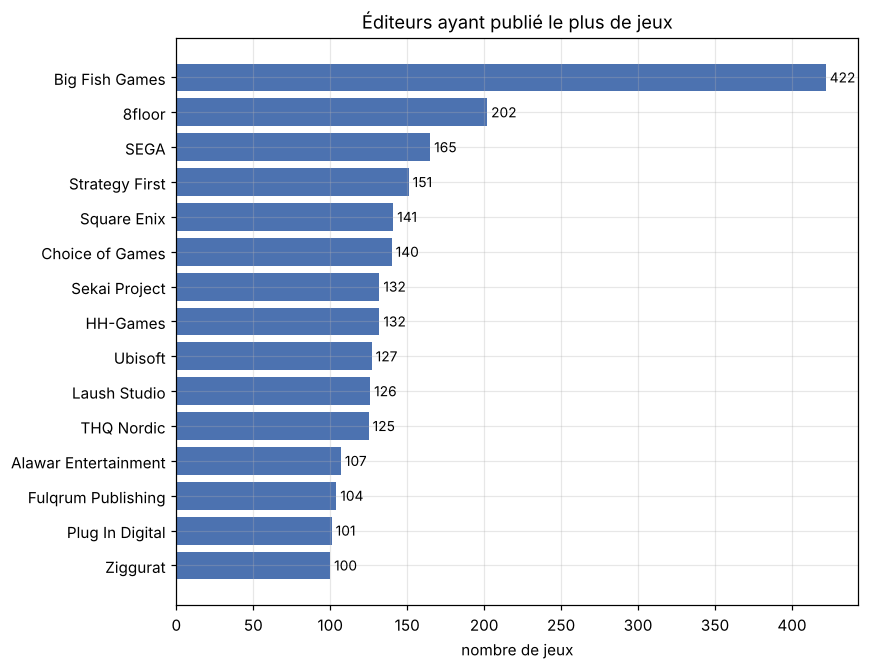

,publisher,jeux,% avis positifs
0,Big Fish Games,422,83.9
1,8floor,202,74.6
2,SEGA,165,85.6
3,Strategy First,151,56.2
4,Square Enix,141,75.2
5,Choice of Games,140,74.0
6,Sekai Project,132,86.5
7,HH-Games,132,72.6
8,Ubisoft,127,77.6
9,Laush Studio,126,78.5


In [3]:
pub = (df.filter(F.col("publisher") != "").groupBy("publisher")
         .agg(F.count("*").alias("jeux"), F.round(F.avg("positive_ratio") * 100, 1).alias("% avis positifs"))
         .orderBy(F.desc("jeux")).limit(15))
pub_pd = pub.toPandas()
barh(pub_pd, "jeux", "publisher", "Éditeurs ayant publié le plus de jeux", "nombre de jeux")
pub_pd

**Lecture.** Le marché est très fragmenté : le premier éditeur, **Big Fish Games** (jeux casual), ne publie que 422 jeux sur 55 690, soit moins de 1 %. **Ubisoft arrive 9e avec 127 jeux** et 77,6 % d'avis positifs, dans la moyenne. Parmi les gros éditeurs, Sekai Project (86,5 %) et SEGA (85,6 %) sont les mieux notés ; Strategy First le moins bien (56,2 %).

### 2.2 Les jeux les mieux notés

In [4]:
best = (df.filter(F.col("reviews") >= 10000)
          .select("name", "publisher", "year", "reviews", F.round(F.col("positive_ratio") * 100, 1).alias("% positifs"))
          .orderBy(F.desc("% positifs"), F.desc("reviews")).limit(15))
best.toPandas()

,name,publisher,year,reviews,% positifs
0,Aseprite,Igara Studio,2016,11903,99.3
1,A Short Hike,adamgryu,2019,11732,99.3
2,Senren＊Banka,"HIKARI FIELD, NekoNyan Ltd.",2020,10677,99.2
3,People Playground,Studio Minus,2019,144569,98.9
4,Portal 2,Valve,2011,309441,98.8
5,Vampire Survivors,poncle,2022,131935,98.8
6,The Room 4: Old Sins,Fireproof Games,2021,10424,98.8
7,ULTRAKILL,New Blood Interactive,2020,40598,98.7
8,The Henry Stickmin Collection,Innersloth,2020,33340,98.7
9,Hades,Supergiant Games,2020,202789,98.6


**Lecture.** Parmi les jeux qui ont au moins 10 000 avis, les mieux notés dépassent tous 98 % d'avis positifs. On y trouve **surtout des studios indépendants** (A Short Hike, Vampire Survivors, ULTRAKILL, Hades) aux côtés de Valve (Portal 2, Half-Life: Alyx). La qualité perçue ne dépend pas de la taille de l'éditeur.

### 2.3 Les sorties par année (et l'effet Covid)

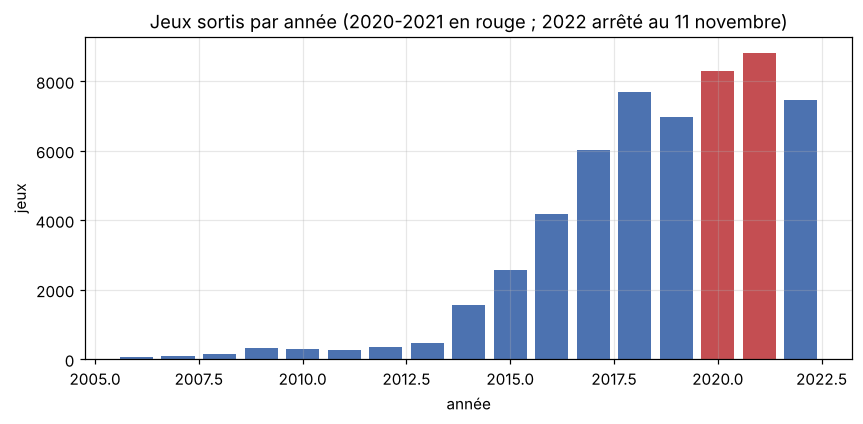

year,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022
count,61,98,159,311,288,267,345,471,1557,2575,4185,6017,7678,6968,8305,8823,7455


In [5]:
years = (df.filter(F.col("year").between(2006, 2022)).groupBy("year").count().orderBy("year"))
y_pd = years.toPandas()
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(y_pd.year, y_pd["count"], color=["#c44e52" if y in (2020, 2021) else "#4c72b0" for y in y_pd.year])
ax.set(title="Jeux sortis par année (2020-2021 en rouge ; 2022 arrêté au 11 novembre)", xlabel="année", ylabel="jeux")
plt.show()
y_pd.set_index("year").T

**Lecture.** Les sorties explosent à partir de 2014 (ouverture de Steam aux indépendants avec Greenlight puis Direct) : de 471 jeux en 2013 à 6 017 en 2017. **La période Covid marque un nouveau record** : 8 305 jeux en 2020, +19 % par rapport à 2019, puis 8 823 en 2021. 2022 n'est pas complète (données arrêtées au 11 novembre) : 7 455 jeux en 10 mois et demi, soit un rythme proche de 2021.

### 2.4 Prix et réductions

+----------------------+------------------+---------------+--------------+
|% de jeux en promotion|remise moyenne (%)|prix médian ($)|prix moyen ($)|
+----------------------+------------------+---------------+--------------+
|                   4.5|              57.6|           4.99|          7.73|
+----------------------+------------------+---------------+--------------+



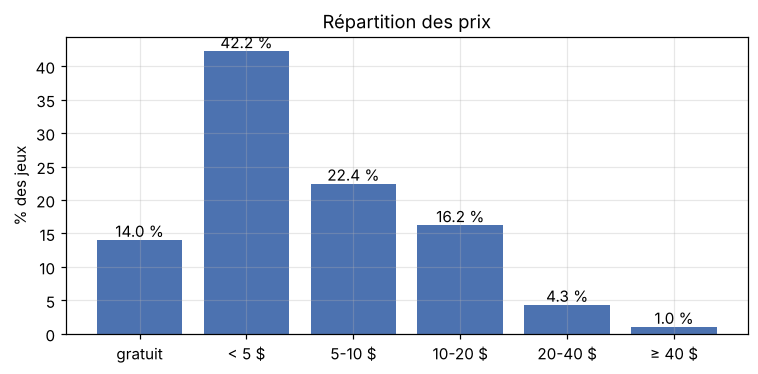

In [6]:
buckets = (df.withColumn("tranche", F.when(F.col("price_usd") == 0, "gratuit")
                                   .when(F.col("price_usd") < 5, "< 5 $")
                                   .when(F.col("price_usd") < 10, "5-10 $")
                                   .when(F.col("price_usd") < 20, "10-20 $")
                                   .when(F.col("price_usd") < 40, "20-40 $")
                                   .otherwise("≥ 40 $"))
             .groupBy("tranche").count())
order = ["gratuit", "< 5 $", "5-10 $", "10-20 $", "20-40 $", "≥ 40 $"]
b_pd = buckets.toPandas().set_index("tranche").loc[order]
b_pd["%"] = (b_pd["count"] / n * 100).round(1)

remise = df.select(
    F.round(F.avg((F.col("discount") > 0).cast("int")) * 100, 1).alias("% de jeux en promotion"),
    F.round(F.avg(F.when(F.col("discount") > 0, F.col("discount"))), 1).alias("remise moyenne (%)"),
    F.round(F.expr("percentile_approx(price_usd, 0.5)"), 2).alias("prix médian ($)"),
    F.round(F.avg("price_usd"), 2).alias("prix moyen ($)"))
remise.show()

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(b_pd.index, b_pd["%"], color="#4c72b0")
for i, v in enumerate(b_pd["%"]):
    ax.text(i, v + 0.5, f"{v} %", ha="center")
ax.set(title="Répartition des prix", ylabel="% des jeux")
plt.show()

**Lecture.** Steam est un marché de **petits prix** : prix médian 4,99 $, 14 % de jeux gratuits, 78,5 % à moins de 10 $ (gratuits compris), seulement 5,3 % à 20 $ et plus. Au moment de l'export, **4,5 % des jeux étaient en promotion**, avec une remise moyenne élevée (−58 %) : les soldes sont rares mais profondes.

### 2.5 Les langues les plus représentées

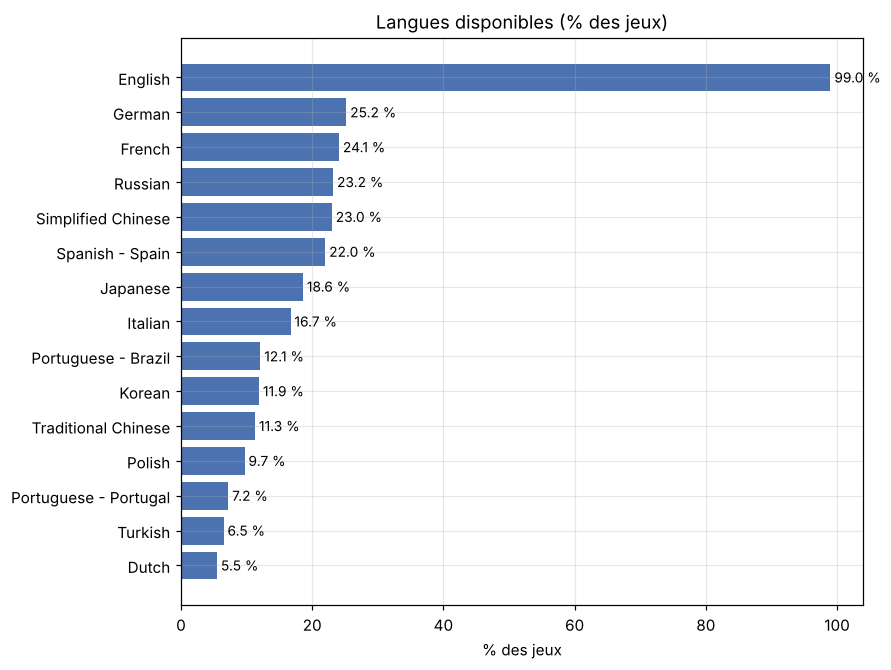

In [7]:
langs = (df.select(F.explode("langs").alias("langue"))
           .withColumn("langue", F.trim("langue"))
           .groupBy("langue").count().orderBy(F.desc("count")).limit(15))
l_pd = langs.toPandas()
l_pd["% des jeux"] = (l_pd["count"] / n * 100).round(1)
barh(l_pd, "% des jeux", "langue", "Langues disponibles (% des jeux)", "% des jeux", fmt="{:.1f} %")

**Lecture.** L'anglais est quasi universel (99 %). Viennent ensuite **l'allemand (25 %), le français (24 %), le russe (23 %), le chinois simplifié (23 %) et l'espagnol (22 %)**, puis le japonais (19 %). Les trois quarts des jeux ne sont donc pas traduits dans les grandes langues européennes ou asiatiques.

### 2.6 Les restrictions d'âge

In [8]:
age = (df.withColumn("classe", F.when(F.col("required_age") >= 18, "18 ans et +")
                               .when(F.col("required_age") >= 16, "16-17 ans")
                               .when(F.col("required_age") > 0, "moins de 16 ans")
                               .otherwise("aucune restriction"))
         .groupBy("classe").count().orderBy(F.desc("count")))
a_pd = age.toPandas()
a_pd["%"] = (a_pd["count"] / n * 100).round(2)
a_pd

,classe,count,%
0,aucune restriction,55029,98.81
1,moins de 16 ans,355,0.64
2,18 ans et +,230,0.41
3,16-17 ans,76,0.14


**Lecture.** **98,8 % des jeux n'ont aucune restriction d'âge** déclarée sur Steam. Les jeux interdits aux moins de 16 ou 18 ans sont marginaux : 0,55 % au total (306 jeux). Le champ est souvent laissé vide par les éditeurs, donc ce chiffre sous-estime probablement les contenus adultes.

## 3. Les genres

### 3.1 Genres les plus représentés et les mieux notés

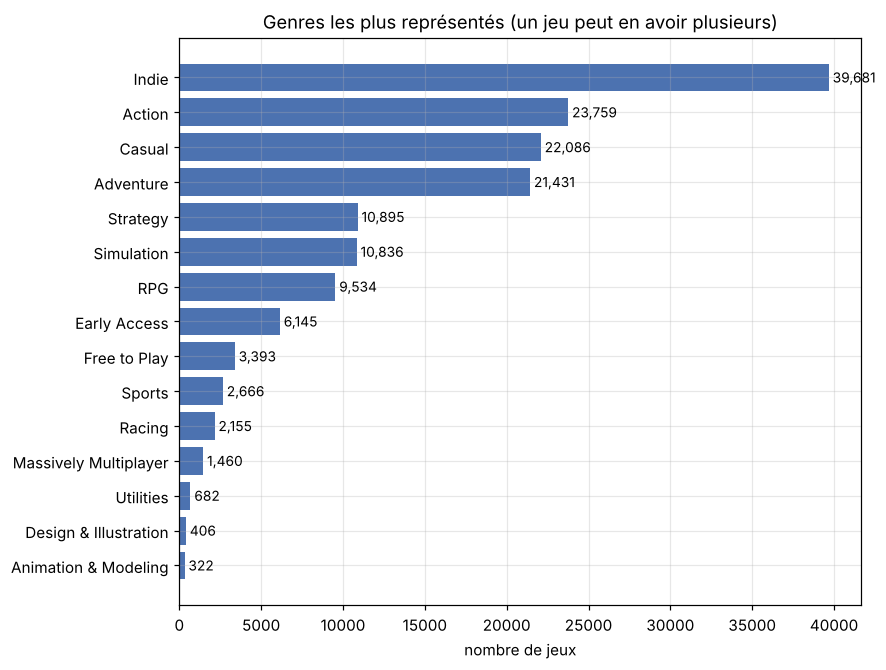

,genre,jeux,% avis positifs (moy.),propriétaires médians,CA estimé (Md$),prix médian ($)
0,Indie,39681,74.2,10000.0,32.35,4.99
1,Action,23759,73.0,10000.0,58.76,4.99
2,Casual,22086,74.3,10000.0,8.08,3.99
3,Adventure,21431,73.9,10000.0,37.25,4.99
4,Strategy,10895,71.9,10000.0,20.15,4.99
5,Simulation,10836,69.4,10000.0,18.77,5.99
6,RPG,9534,73.1,10000.0,27.17,5.99
7,Early Access,6145,70.7,10000.0,5.46,6.99
8,Free to Play,3393,72.2,35000.0,0.10,0.00
9,Sports,2666,69.8,10000.0,3.15,4.99


In [9]:
g = df.select("appid", "positive_ratio", "reviews", "owners_mid", "est_revenue", "price_usd", "publisher",
              "windows", "mac", "linux", F.explode("genres").alias("genre"))
gstats = (g.groupBy("genre")
           .agg(F.count("*").alias("jeux"),
                F.round(F.avg("positive_ratio") * 100, 1).alias("% avis positifs (moy.)"),
                F.round(F.expr("percentile_approx(owners_mid, 0.5)")).alias("propriétaires médians"),
                F.round(F.sum("est_revenue") / 1e9, 2).alias("CA estimé (Md$)"),
                F.round(F.expr("percentile_approx(price_usd, 0.5)"), 2).alias("prix médian ($)"))
           .filter(F.col("jeux") >= 200).orderBy(F.desc("jeux")))
gs_pd = gstats.toPandas()
barh(gs_pd.head(15), "jeux", "genre", "Genres les plus représentés (un jeu peut en avoir plusieurs)", "nombre de jeux")
gs_pd

**Lecture.** **« Indie » est présent sur 71 % des jeux** (39 681), suivi d'Action (43 %), Casual (40 %) et Adventure (38 %). Un jeu ayant en moyenne plusieurs genres, les totaux dépassent 100 %. Le jeu médian a 10 000 propriétaires (la fourchette la plus basse) quel que soit le genre, sauf **Free to Play et Massively Multiplayer (35 000)** : la gratuité élargit l'audience.

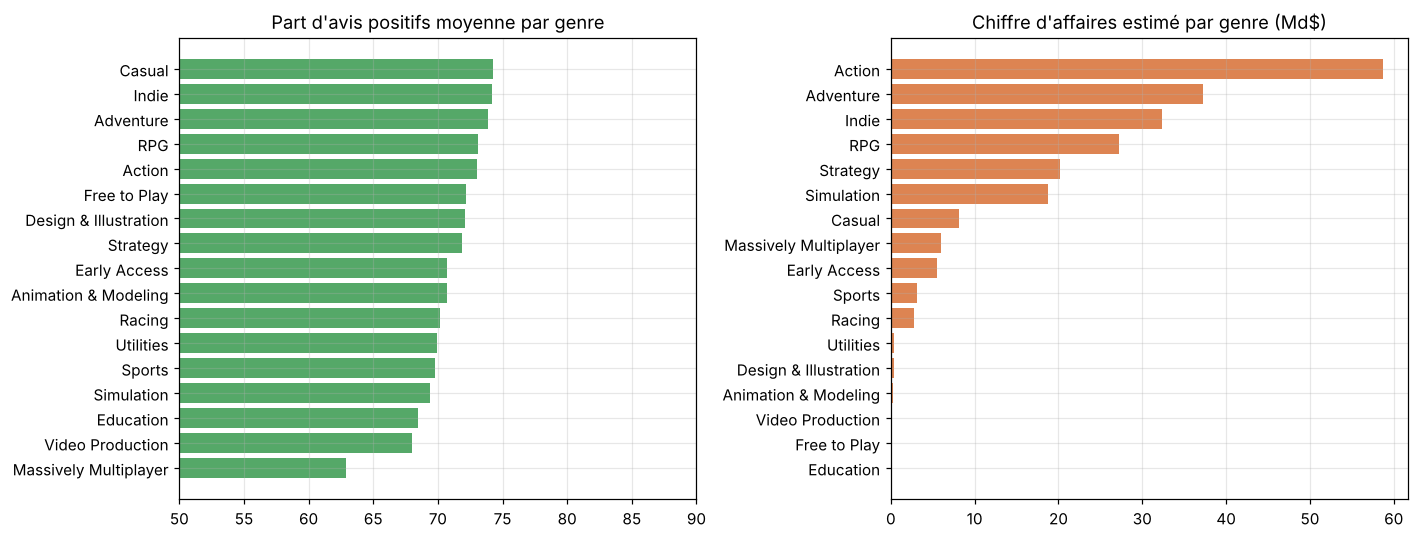

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
r = gs_pd.sort_values("% avis positifs (moy.)", ascending=False)
axes[0].barh(r.genre[::-1], r["% avis positifs (moy.)"][::-1], color="#55a868")
axes[0].set(title="Part d'avis positifs moyenne par genre", xlim=(50, 90))
c = gs_pd.sort_values("CA estimé (Md$)", ascending=False)
axes[1].barh(c.genre[::-1], c["CA estimé (Md$)"][::-1], color="#dd8452")
axes[1].set(title="Chiffre d'affaires estimé par genre (Md$)")
plt.tight_layout()
plt.show()

**Lecture.**
- **Ratio d'avis positifs** : les écarts entre genres sont faibles (69 à 74 %), avec Casual, Indie et Adventure en tête. **Massively Multiplayer est nettement en dessous (63 %, contre 74 % tous jeux confondus)** : les jeux en ligne massifs déçoivent davantage.
- **Chiffre d'affaires estimé** (propriétaires × prix actuel, une approximation grossière) : **Action domine (59 Md$)**, devant Adventure (37 Md$), Indie (32 Md$) et RPG (27 Md$). Les Free to Play apparaissent à 0 car leurs revenus viennent des achats en jeu, absents des données : ce n'est pas un genre non rentable.

### 3.2 Les éditeurs ont-ils des genres favoris ?

In [11]:
top_pub = [r.publisher for r in pub.limit(8).collect()]
pg = (g.filter(F.col("publisher").isin(top_pub)).groupBy("publisher", "genre").count())
w = Window.partitionBy("publisher").orderBy(F.desc("count"))
tot = df.filter(F.col("publisher").isin(top_pub)).groupBy("publisher").agg(F.count("*").alias("total"))
fav = (pg.withColumn("rang", F.row_number().over(w)).filter("rang <= 2").join(tot, "publisher")
         .withColumn("% des jeux de l'éditeur", F.round(F.col("count") / F.col("total") * 100, 1))
         .orderBy("publisher", "rang"))
fav.toPandas()

,publisher,genre,count,rang,total,% des jeux de l'éditeur
0,8floor,Casual,202,1,202,100.0
1,8floor,Strategy,22,2,202,10.9
2,Big Fish Games,Casual,418,1,422,99.1
3,Big Fish Games,Adventure,392,2,422,92.9
4,Choice of Games,RPG,139,1,140,99.3
5,Choice of Games,Indie,136,2,140,97.1
6,HH-Games,Casual,132,1,132,100.0
7,HH-Games,Indie,69,2,132,52.3
8,SEGA,Action,80,1,165,48.5
9,SEGA,Adventure,33,2,165,20.0


**Lecture.** Oui, la plupart des gros éditeurs sont spécialisés : **Big Fish Games, 8floor et HH-Games publient presque exclusivement du Casual** (99 à 100 %), **Choice of Games du RPG textuel** (99 %). Les éditeurs « AAA » sont plus diversifiés : SEGA et Square Enix ont environ la moitié de leurs jeux en Action, Square Enix autant en RPG.

## 4. Les plateformes

+-------+----+-----+
|windows| mac|linux|
+-------+----+-----+
|  100.0|22.9| 15.2|
+-------+----+-----+



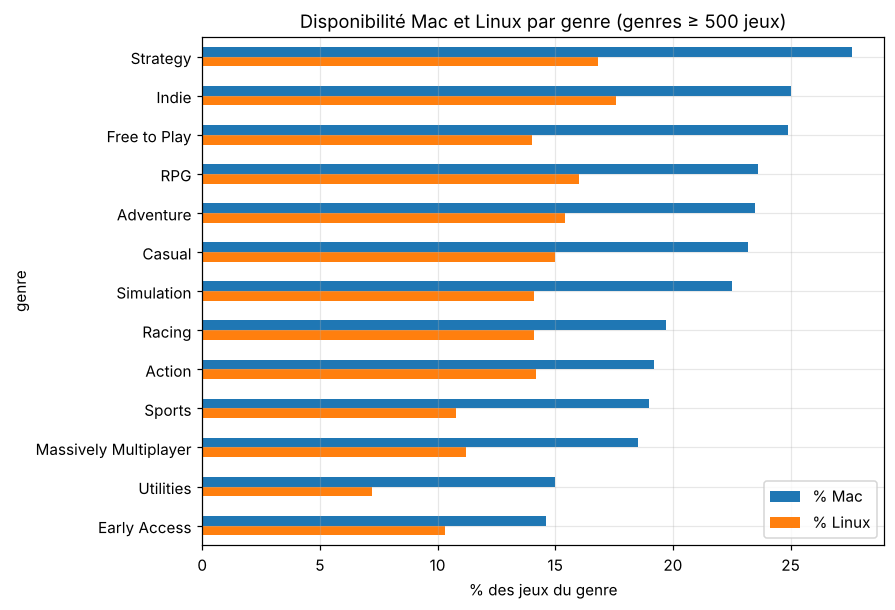

,genre,jeux,% Mac,% Linux
0,Strategy,10895,27.6,16.8
1,Indie,39681,25.0,17.6
2,Free to Play,3393,24.9,14.0
3,RPG,9534,23.6,16.0
4,Adventure,21431,23.5,15.4
5,Casual,22086,23.2,15.0
6,Simulation,10836,22.5,14.1
7,Racing,2155,19.7,14.1
8,Action,23759,19.2,14.2
9,Sports,2666,19.0,10.8


In [12]:
plat = df.select(*[F.round(F.avg(F.col(p).cast("int")) * 100, 1).alias(p) for p in ["windows", "mac", "linux"]])
plat.show()
gp = (g.groupBy("genre").agg(F.count("*").alias("jeux"),
                             F.round(F.avg(F.col("mac").cast("int")) * 100, 1).alias("% Mac"),
                             F.round(F.avg(F.col("linux").cast("int")) * 100, 1).alias("% Linux"))
        .filter("jeux >= 500").orderBy(F.desc("% Mac")))
gp_pd = gp.toPandas()
ax = gp_pd.set_index("genre")[["% Mac", "% Linux"]].plot.barh(figsize=(8, 6))
ax.invert_yaxis(); ax.set(title="Disponibilité Mac et Linux par genre (genres ≥ 500 jeux)", xlabel="% des jeux du genre")
plt.show()
gp_pd

**Lecture.** **100 % des jeux tournent sous Windows**, seulement 23 % sur Mac et 15 % sur Linux. La compatibilité varie peu selon le genre : Strategy (28 % Mac) et Indie (25 %) sont les mieux portés, Early Access (15 %) et Utilities les moins. Un jeu en accès anticipé se concentre d'abord sur Windows.

## 5. Qu'est-ce qui fait un jeu populaire ?

On mesure la popularité par le **nombre de propriétaires** (milieu de la fourchette SteamSpy) et on regarde, pour chaque facteur, la **part de jeux qui atteignent au moins 100 000 propriétaires** (12 % des jeux). Ce sont des associations, pas des causes.

Jeux à ≥ 100 000 propriétaires : 11.9%


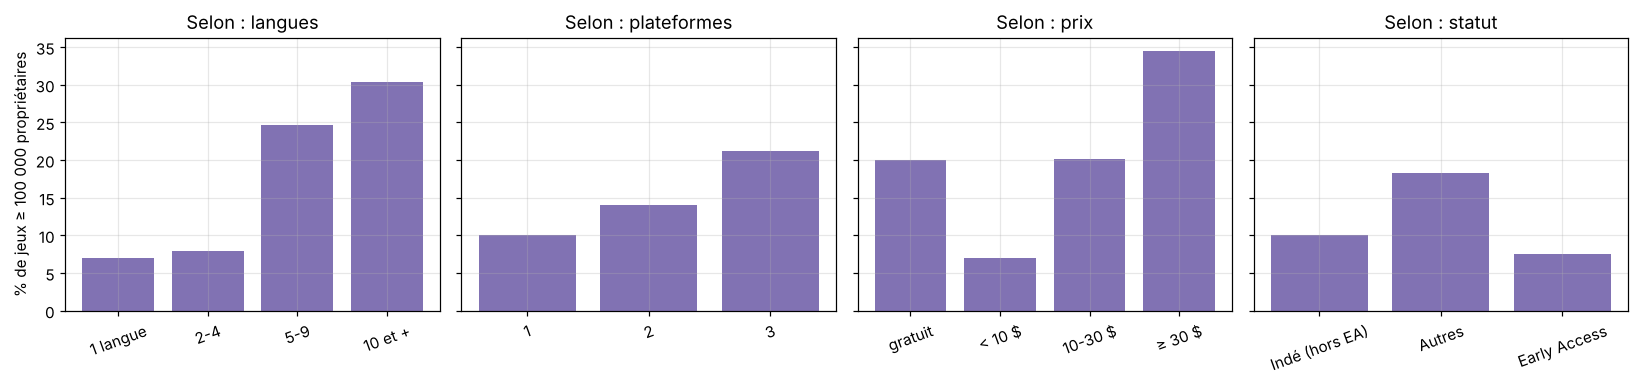

jeux  % ≥ 100k propriétaires
langues     1 langue        29665                     7.0
            2-4             13026                     7.9
            5-9              7376                    24.7
            10 et +          5623                    30.4
plateformes 1               41285                    10.0
            2                7599                    14.0
            3                6806                    21.2
prix        gratuit          7779                    20.0
            < 10 $          35928                     7.0
            10-30 $         10816                    20.1
            ≥ 30 $           1167                    34.5
statut      Indé (hors EA)  34843                    10.0
            Autres          14702                    18.3
            Early Access     6145                     7.6

In [13]:
df2 = df.withColumn("succes", (F.col("owners_low") >= 100000).cast("int"))
print(f"Jeux à ≥ 100 000 propriétaires : {df2.agg(F.avg('succes')).first()[0]:.1%}")

def taux(col_expr, nom, ordre=None):
    t = (df2.withColumn(nom, col_expr).groupBy(nom)
            .agg(F.count("*").alias("jeux"), F.round(F.avg("succes") * 100, 1).alias("% ≥ 100k propriétaires")).toPandas())
    if ordre: t = t.set_index(nom).loc[ordre].reset_index()
    return t

t_lang = taux(F.when(F.col("n_langs") <= 1, "1 langue").when(F.col("n_langs") <= 4, "2-4").when(F.col("n_langs") <= 9, "5-9").otherwise("10 et +"),
              "langues", ["1 langue", "2-4", "5-9", "10 et +"])
t_plat = taux(F.col("n_platforms").cast("string"), "plateformes", ["1", "2", "3"])
t_prix = taux(F.when(F.col("price_usd") == 0, "gratuit").when(F.col("price_usd") < 10, "< 10 $").when(F.col("price_usd") < 30, "10-30 $").otherwise("≥ 30 $"),
              "prix", ["gratuit", "< 10 $", "10-30 $", "≥ 30 $"])
t_early = taux(F.when(F.array_contains("genres", "Early Access"), "Early Access").when(F.array_contains("genres", "Indie"), "Indé (hors EA)").otherwise("Autres"), "statut")

fig, axes = plt.subplots(1, 4, figsize=(15, 3.6), sharey=True)
for ax, (t, nom) in zip(axes, [(t_lang, "langues"), (t_plat, "plateformes"), (t_prix, "prix"), (t_early, "statut")]):
    ax.bar(t[nom], t["% ≥ 100k propriétaires"], color="#8172b3")
    ax.set(title=f"Selon : {nom}", ylabel="% de jeux ≥ 100 000 propriétaires" if nom == "langues" else "")
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()
pd.concat({"langues": t_lang.set_index("langues"), "plateformes": t_plat.set_index("plateformes"),
           "prix": t_prix.set_index("prix"), "statut": t_early.set_index("statut")})

**Lecture.** 12 % des jeux atteignent au moins 100 000 propriétaires. Ce taux varie fortement selon :
- **les langues** : 7 % pour un jeu en 1 langue, **30 % à partir de 10 langues**. C'est l'écart le plus net ;
- **les plateformes** : 10 % sur Windows seul, **21 % sur les trois plateformes** ;
- **le prix** : 7 % sous 10 $, 20 % pour les gratuits, **35 % à 30 $ et plus**. Un prix élevé n'attire pas en soi : il signale un jeu à gros budget, mieux marketé ;
- **le statut** : les jeux en Early Access réussissent moins (8 %) que les autres jeux non indépendants (18 %).

Ce sont des associations, pas des causes : un gros studio traduit plus, porte sur plus de plateformes et vend plus cher.

In [14]:
corr = df.filter(F.col("reviews") >= 50).select(
    F.corr(F.log1p("owners_mid"), F.col("n_langs")).alias("log(propriétaires) ~ langues"),
    F.corr(F.log1p("owners_mid"), F.col("n_platforms")).alias("log(propriétaires) ~ plateformes"),
    F.corr(F.log1p("owners_mid"), F.col("price_usd")).alias("log(propriétaires) ~ prix"),
    F.corr(F.col("positive_ratio"), F.log1p("owners_mid")).alias("avis positifs ~ log(propriétaires)"))
corr.select([F.round(c, 2).alias(c) for c in corr.columns]).show(truncate=False)

+----------------------------+--------------------------------+-------------------------+----------------------------------+
|log(propriétaires) ~ langues|log(propriétaires) ~ plateformes|log(propriétaires) ~ prix|avis positifs ~ log(propriétaires)|
+----------------------------+--------------------------------+-------------------------+----------------------------------+
|0.22                        |0.08                            |0.09                     |0.07                              |
+----------------------------+--------------------------------+-------------------------+----------------------------------+



**Lecture.** Sur les jeux d'au moins 50 avis, **le nombre de langues est le facteur le plus lié au nombre de propriétaires** (r = 0,22), loin devant les plateformes et le prix (≈ 0,1). La qualité perçue n'est presque pas liée à la popularité (r = 0,07) : un jeu très apprécié peut rester confidentiel.

## 6. Conclusions pour Ubisoft

| Constat | Chiffre clé | Recommandation pour Ubisoft |
| --- | --- | --- |
| Marché saturé, très fragmenté | 55 690 jeux, 8 000+ sorties par an depuis 2020 | Se différencier par la visibilité, pas par le volume |
| La traduction est le facteur le plus lié au succès | 30 % de succès à 10 langues et +, contre 7 % à 1 langue | Sortir en 10 langues au moins : allemand, français, russe, chinois, espagnol, japonais en priorité |
| La compatibilité multi-plateforme aide | 21 % sur 3 plateformes, contre 10 % sur Windows seul | Prévoir Mac et Linux (ou Steam Deck) dès la sortie |
| Action reste le genre le plus lucratif | 59 Md$ de CA estimé | Viser Action, éventuellement Action-RPG (27 Md$ pour RPG) |
| Les jeux très bien notés sont souvent indépendants | > 98 % d'avis positifs | La qualité et l'originalité priment sur le budget |
| Les MMO déçoivent | 63 % d'avis positifs contre 74 % en moyenne | Éviter le massivement multijoueur, ou investir fortement dans le service |
| Les soldes sont rares mais fortes | 4,5 % en promo, −58 % en moyenne | Prévoir des promotions ponctuelles et profondes |

**Limites.** Le nombre de propriétaires est une fourchette SteamSpy, le chiffre d'affaires une estimation (prix actuel × milieu de fourchette, hors achats en jeu), et les données s'arrêtent en novembre 2022.